In [1]:
from PIL import Image
import numpy as np
import matplotlib.pyplot as plt
import cv2

Gambar asli shape: (956, 736, 3)
Gambar setelah resize shape: (256, 256, 3)


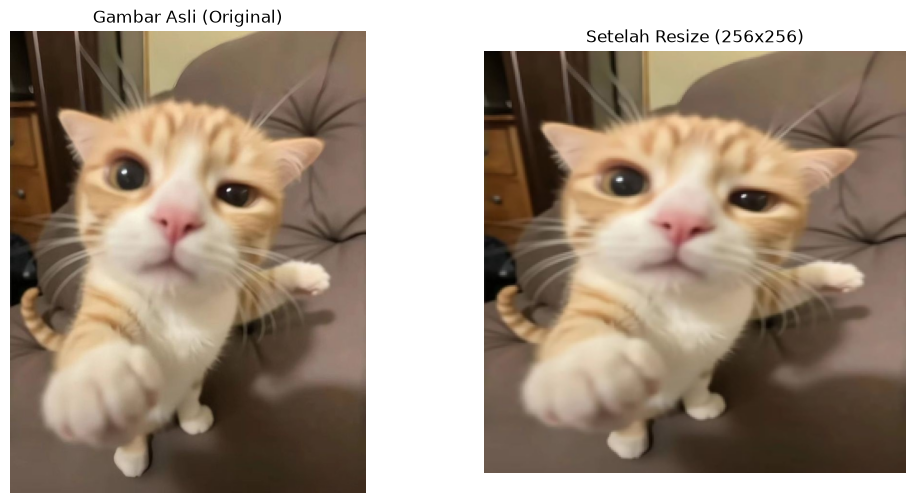

In [2]:
from pathlib import Path
# LOAD DAN TAMPILKAN GAMBAR
img_path = str(Path.cwd().parent / "data" / "sample_image.jpeg")

try:
    img_color_ori = Image.open(img_path).convert('RGB')
    img_color = img_color_ori.resize((256, 256))
    img_color_np = np.array(img_color, dtype=np.float32)
    img_color_ori_np = np.array(img_color_ori, dtype=np.float32)
    print("Gambar asli shape:", img_color_ori_np.shape)
    print("Gambar setelah resize shape:", img_color_np.shape)

    plt.figure(figsize=(12, 6))
    plt.subplot(1, 2, 1)
    plt.imshow(img_color_ori_np.astype('uint8'))
    plt.title("Gambar Asli (Original)")
    plt.axis('off')

    plt.subplot(1, 2, 2)
    plt.imshow(img_color_np.astype('uint8'))
    plt.title("Setelah Resize (256x256)")
    plt.axis('off')
    plt.show()

except Exception as e:
    print("Gagal memuat gambar:", e)

In [3]:
# DEFINISI MATRISKUANTISASI DAN DCT
Q_base = np.array([
    [16, 11, 10, 16, 24, 40, 51, 61],
    [12, 12, 14, 19, 26, 58, 60, 55],
    [14, 13, 16, 24, 40, 57, 69, 56],
    [14, 17, 22, 29, 51, 87, 80, 62],
    [18, 22, 37, 56, 68, 109, 103, 77],
    [24, 35, 55, 64, 81, 104, 113, 92],
    [49, 64, 78, 87, 103, 121, 120, 101],
    [72, 92, 95, 98, 112, 100, 103, 99]
], dtype=np.float32)

quality_factor = 5  # Semakin tinggi, semakin bagus kualitas
Q = Q_base * quality_factor

In [4]:
# Proses Lossy: DCT + KUANTISASI
def compress_channel(channel):
    h, w = channel.shape
    compressed = np.zeros_like(channel)
    reconstructed = np.zeros_like(channel)
    
    for i in range(0, h, 8):
        for j in range(0, w, 8):
            block = channel[i:i+8, j:j+8] - 128
            dct_block = cv2.dct(block)
            quantized = np.round(dct_block / Q)
            compressed[i:i+8, j:j+8] = quantized + 128
            idct_block = cv2.idct(quantized * Q) + 128
            reconstructed[i:i+8, j:j+8] = np.clip(idct_block, 0, 255)
    
    return compressed.astype('uint8'), reconstructed.astype('uint8')

compressed_color = []
reconstructed_color = []

for c in range(3):  # Untuk R, G, B
    comp, recon = compress_channel(img_color_np[:, :, c])
    compressed_color.append(comp)
    reconstructed_color.append(recon)

compressed_color_img = np.stack(compressed_color, axis=2)
reconstructed_color_img = np.stack(reconstructed_color, axis=2)

In [5]:
# HITUNG PSNR
def calculate_psnr(original, compressed):
    mse = np.mean((original - compressed) ** 2)
    if mse == 0:
        return float('inf')
    return 20 * np.log10(255.0 / np.sqrt(mse))

psnr_color = calculate_psnr(img_color_np, reconstructed_color_img)


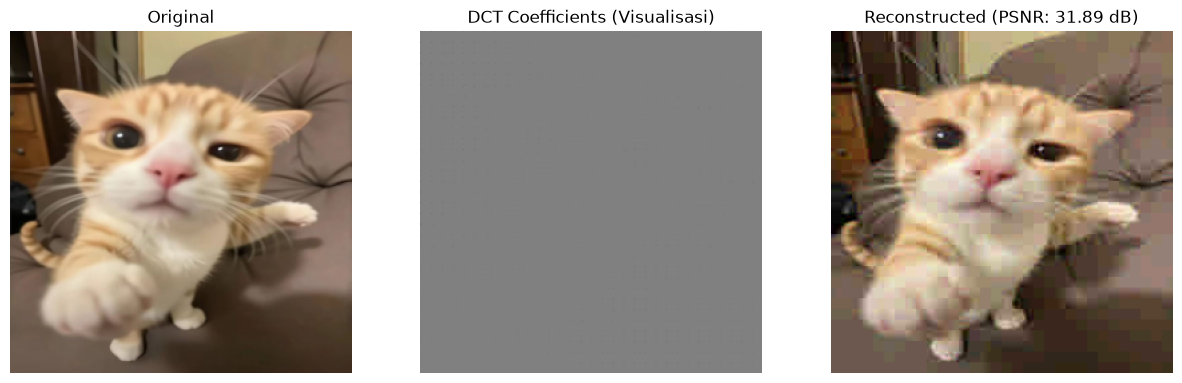

PSNR Citra Warna setelah Kompresi: 31.89 dB


In [6]:
# VISUALISASI HASIL
plt.figure(figsize=(15, 5))
plt.subplot(1, 3, 1)
plt.imshow(img_color_np.astype('uint8'))
plt.title("Original")
plt.axis('off')

plt.subplot(1, 3, 2)
plt.imshow(compressed_color_img)
plt.title("DCT Coefficients (Visualisasi)")
plt.axis('off')

plt.subplot(1, 3, 3)
plt.imshow(reconstructed_color_img)
plt.title(f"Reconstructed (PSNR: {psnr_color:.2f} dB)")
plt.axis('off')
plt.show()

print(f"PSNR Citra Warna setelah Kompresi: {psnr_color:.2f} dB")


In [7]:
# KONVERSI BITSTREAM DAN CHANNEL CODING

# Bitstream encoding dan decoding
def image_to_bitstream(img_array):
    return ''.join(format(byte, '08b') for byte in img_array.tobytes())

def bitstream_to_image(bitstream, shape, dtype):
    bytes_data = bytearray(int(bitstream[i:i+8], 2) for i in range(0, len(bitstream), 8))
    return np.frombuffer(bytes_data, dtype=dtype).reshape(shape)

# Hamming encoding dan decoding
def add_hamming_code(bitstream):
    encoded = []
    for i in range(0, len(bitstream), 4):
        d = bitstream[i:i+4].ljust(4, '0')
        p1 = str(int(d[0]) ^ int(d[1]) ^ int(d[3]))
        p2 = str(int(d[0]) ^ int(d[2]) ^ int(d[3]))
        p3 = str(int(d[1]) ^ int(d[2]) ^ int(d[3]))
        encoded.append(p1 + p2 + d[0] + p3 + d[1] + d[2] + d[3])
    return ''.join(encoded)

def detect_and_correct_hamming(encoded_bitstream):
    corrected = []
    errors = []
    for i in range(0, len(encoded_bitstream), 7):
        block = encoded_bitstream[i:i+7]
        if len(block) < 7:
            corrected.append(block)
            continue
        p1, p2, d1, p3, d2, d3, d4 = block
        s1 = str(int(p1)^int(d1)^int(d2)^int(d4))
        s2 = str(int(p2)^int(d1)^int(d3)^int(d4))
        s3 = str(int(p3)^int(d2)^int(d3)^int(d4))
        # Hamming(7,4): parity is at positions 1, 2, 4, so the check covering position 1
        # is the LEAST significant syndrome bit. Order is s3 s2 s1, not s1 s2 s3.
        syndrome = s3 + s2 + s1
        pos = int(syndrome, 2) - 1
        if pos >= 0:
            block = list(block)
            block[pos] = '0' if block[pos] == '1' else '1'
            errors.append(i + pos)
        corrected.append(''.join(block))
    return ''.join(corrected), errors

def remove_hamming_code(encoded_bitstream):
    return ''.join(encoded_bitstream[i+2] + encoded_bitstream[i+4] + encoded_bitstream[i+5] + encoded_bitstream[i+6]
                   for i in range(0, len(encoded_bitstream), 7))

# Simulasi noise
def introduce_errors(bitstream, error_prob=0.005):
    bitstream = list(bitstream)
    errors = []
    for i in range(len(bitstream)):
        if np.random.rand() < error_prob:
            bitstream[i] = '1' if bitstream[i] == '0' else '0'
            errors.append(i)
    return ''.join(bitstream), errors

# Proses channel coding
bitstream = image_to_bitstream(compressed_color_img)
encoded = add_hamming_code(bitstream)
corrupted, actual_errors = introduce_errors(encoded)
corrected, detected_errors = detect_and_correct_hamming(corrupted)
decoded = remove_hamming_code(corrected)
recovered_img = bitstream_to_image(decoded, compressed_color_img.shape, compressed_color_img.dtype)


In [8]:
# DEKOMPRESI CITRA
def decompress_channel(channel):
    h, w = channel.shape
    output = np.zeros_like(channel, dtype=np.float32)
    for i in range(0, h, 8):
        for j in range(0, w, 8):
            quantized = channel[i:i+8, j:j+8].astype(np.float32) - 128
            idct_block = cv2.idct(quantized * Q) + 128
            output[i:i+8, j:j+8] = np.clip(idct_block, 0, 255)
    return output.astype('uint8')

final_reconstructed = np.stack([decompress_channel(recovered_img[:,:,c]) for c in range(3)], axis=2)
psnr_final = calculate_psnr(img_color_np, final_reconstructed)

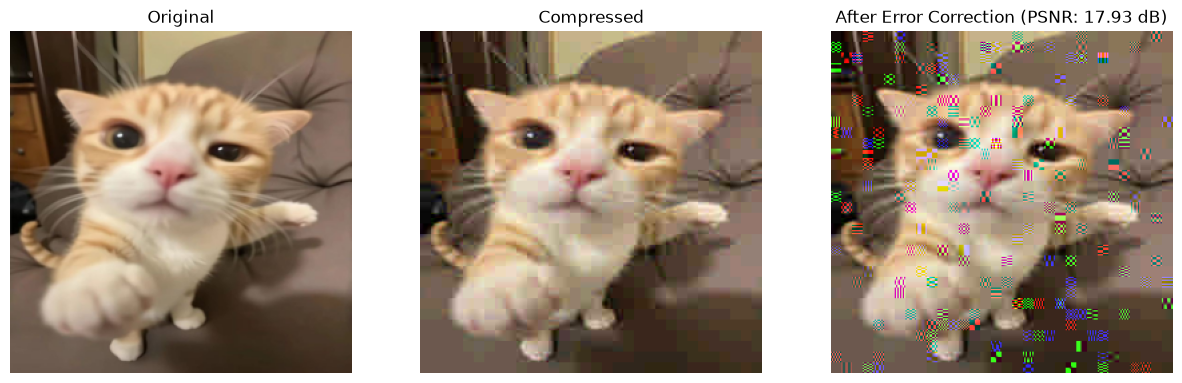


Ringkasan:
- PSNR Kompresi Awal      : 31.89 dB
- Jumlah Error Disisipkan : 13711
- Jumlah Error Terdeteksi : 13503
- PSNR Setelah Koreksi    : 17.93 dB


In [9]:
# VISUALISASI HASIL AKHIR
plt.figure(figsize=(15, 5))
plt.subplot(1, 3, 1)
plt.imshow(img_color_np.astype('uint8'))
plt.title("Original")
plt.axis('off')

plt.subplot(1, 3, 2)
plt.imshow(reconstructed_color_img)
plt.title("Compressed")
plt.axis('off')

plt.subplot(1, 3, 3)
plt.imshow(final_reconstructed)
plt.title(f"After Error Correction (PSNR: {psnr_final:.2f} dB)")
plt.axis('off')
plt.show()

# RINGKASAN
print("\nRingkasan:")
print(f"- PSNR Kompresi Awal      : {psnr_color:.2f} dB")
print(f"- Jumlah Error Disisipkan : {len(actual_errors)}")
print(f"- Jumlah Error Terdeteksi : {len(detected_errors)}")
print(f"- PSNR Setelah Koreksi    : {psnr_final:.2f} dB")